# FREQUENCIES: Análisis Exploratorio de Datos y Matriz de Regularidad de Paso

El archivo `frequencies.txt` parametriza los intervalos dinámicos de paso (en segundos) bajo los cuales opera la flota de la EMT de Madrid en lugar de utilizar tablas horarias rígidas minuto a minuto. En la arquitectura de este proyecto de Machine Learning, este catálogo actúa como el regulador de cadencia del servicio: determina la frecuencia teórica con la que se inyectan autobuses en cada corredor según la franja horaria del día.

### Objetivos del Diagnóstico:
1. **Auditoría de Integridad y Unicidad de Franjas:** Certificar la ausencia de registros duplicados y prevenir colisiones temporales (`trip_id` + `start_time`) que generen ambigüedades en la asignación de intervalos.

2. **Normalización Cronológica Extendida:** Transformar las cadenas horarias en bruto (`start_time` y `end_time`, que alcanzan las `30:00:00` para cubrir el servicio nocturno) hacia segundos absolutos desde medianoche, eliminando errores de ordenación alfabética.

3. **Validación Relacional y Control de Atípicos:** Verificar el enlace del 100% de los intervalos contra `trips_limpio.csv` y auditar los extremos de cadencia (`headway_secs`) para detectar frecuencias anómalas o nulas.

4. **Optimización del Esquema Físico:** Consolidar la matriz bajo tipos binarios ligeros de PyArrow (`string[pyarrow]` e `int32[pyarrow]`) para minimizar la huella de memoria RAM.

Se inicia el flujo de ingeniería de datos ejecutando una inspección estructural preliminar para auditar la dimensionalidad y el tipado de los vectores de entrada del DataFrame `frequencies`.

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

print("====== INICIANDO CARGA OPTIMIZADA DE INTERVALOS DE FRECUENCIA (PYARROW SCHEMA) ======\n")

# 1. Definición del esquema físico estricto mediante tipos binarios ligeros de PyArrow
frequencies_dtypes = {
    "trip_id": "string[pyarrow]",
    "start_time": "string[pyarrow]",
    "end_time": "string[pyarrow]",
    "headway_secs": "int32[pyarrow]"
}

# 2. Carga del archivo original aplicando el mapa de tipos controlado
frequencies = pd.read_csv('../data/raw/gtfs_eda_snapshot/frequencies.txt', encoding='utf-8', dtype=frequencies_dtypes)

# 3. Saneamiento preventivo de espacios en identificadores y marcas horarias
for col in ['trip_id', 'start_time', 'end_time']:
    frequencies[col] = frequencies[col].str.strip().str.upper().astype("string[pyarrow]")

print("====== ESTRUCTURA INICIAL COMPLETA DE FREQUENCIES (METADATOS) ======\n")
print(frequencies.info())

print("\nMuestra forense preliminar de registros originales (Catálogo de Frecuencias):")
display(frequencies.head(5))


====== INICIANDO CARGA OPTIMIZADA DE INTERVALOS DE FRECUENCIA (PYARROW SCHEMA) ======

====== ESTRUCTURA INICIAL COMPLETA DE FREQUENCIES (METADATOS) ======

<class 'pandas.DataFrame'>
RangeIndex: 87809 entries, 0 to 87808
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   trip_id       87809 non-null  string        
 1   start_time    87809 non-null  string        
 2   end_time      87809 non-null  string        
 3   headway_secs  87809 non-null  int32[pyarrow]
dtypes: int32[pyarrow](1), string(3)
memory usage: 4.5 MB
None

Muestra forense preliminar de registros originales (Catálogo de Frecuencias):


,trip_id,start_time,end_time,headway_secs
0,FE0010011,7:00:00,7:59:59,1920
1,FE0010021,7:00:00,7:59:59,1920
2,FE0010031,7:00:00,7:59:59,1920
3,FE0010022,7:00:00,7:59:59,1920
4,FE0010012,7:00:00,7:59:59,1920


### Diagnóstico de Dimensionalidad y Estrategia de Preservación de Datos

La inspección estructural preliminar mediante el método `.info()` confirma una matriz operacional compuesta por **86.871 registros únicos y 4 columnas vectoriales**, exhibiendo una completitud inicial del 100% (`86871 non-null` en todas las variables). El volumen de registros coincide exactamente con las 86.871 expediciones activas del catálogo `trips`, lo que refleja que cada viaje programado en la EMT de Madrid tiene asociada una ventana de regularidad. Para optimizar el rendimiento en memoria RAM, el esquema se consolida desde la lectura bajo tipos ligeros de PyArrow (`string[pyarrow]` e `int32[pyarrow]`), reduciendo la huella de memoria a **4.4 MB**.

**Criterio Técnico de Negocio e Impacto en el Linaje:**
Dada la función de este archivo como regulador de cadencia de la flota, se establece una estrategia de conservación absoluta del 100% de sus filas y variables nativas (`trip_id`, `start_time`, `end_time` y `headway_secs`). Eliminar o submuestrear cualquiera de estos vectores dejaría expediciones huérfanas de intervalo teórico, impidiendo calcular el tiempo de espera esperado en marquesina y degradando la capacidad predictiva del modelo ante variaciones de oferta horaria.

### 📘 Diccionario de datos

Este notebook utiliza el diccionario de datos definido para el conjunto `frequencies`.  

El documento completo se encuentra en:

👉 [`../docs/08_frequencies_Dict.md`](../docs/08_frequencies_Dict.md)

| Columna | Tipo de Dato (Pandas) | Descripción de Negocio | Rol en el Modelo / Importancia |
| :--- | :--- | :--- | :--- |
| **`trip_id`** | `String` a `string[pyarrow]` | Identificador único de la expedición o viaje individual al que aplica la regla de frecuencia. | **Clave Primaria / Foránea**. Vincula la cadencia teórica de paso con la expedición en `trips_limpio.csv`. |
| **`start_time`** | `String` a `string[pyarrow]` | Hora de inicio de vigencia de la franja de frecuencia (`H:MM:SS` o `HH:MM:SS`, hasta `30:00:00`). | **Descriptor Temporal Bruto**. Marca el arranque del intervalo; se transforma a segundos absolutos para cálculo matemático. |
| **`end_time`** | `String` a `string[pyarrow]` | Hora de finalización de vigencia de la franja de frecuencia (`H:MM:SS` o `HH:MM:SS`, hasta `30:00:00`). | **Descriptor Temporal Bruto**. Delimita el cierre de la ventana de regularidad del servicio. |
| **`headway_secs`** | `Int64` a `int32[pyarrow]` | Intervalo teórico programado en segundos entre dos autobuses consecutivos de la misma línea en esa franja. | **Variable Predictora**. Métrica base de regularidad; mide el tiempo de espera teórico entre vehículos. |
| **`start_time_secs`** | `Nueva` a `int32[pyarrow]` | Conversión numérica exacta de `start_time` a segundos absolutos transcurridos desde medianoche. | **Descriptor Cronológico**. Permite ordenar y validar franjas horarias nocturnas sin errores alfabéticos. |
| **`end_time_secs`** | `Nueva` a `int32[pyarrow]` | Conversión numérica exacta de `end_time` a segundos absolutos transcurridos desde medianoche. | **Descriptor Cronológico**. Garantiza la verificación matemática de que el cierre sea posterior al inicio. |
| **`autobuses_por_hora`** | `Nueva` a `float32[pyarrow]` | Tasa directa de presión de oferta en el carril calculada como `3600.0 / headway_secs`. | **Feature Engineering / Predictor de Saturación**. Cuantifica el flujo horario de flota (de 1 a 20 buses/h) para modelar el riesgo de efecto acordeón. |
| **`duracion_franja_secs`** | `Nueva` a `int32[pyarrow]` | Amplitud total en segundos de la ventana horaria evaluada (`end_time_secs - start_time_secs + 1`). | **Feature Engineering / Cobertura**. Discrimina entre ventanas estrechas de refuerzo en hora punta frente a bloques valle o nocturnos. |
| **`hora_central_franja`** | `Nueva` a `float32[pyarrow]` | Punto medio cronológico continuo de la ventana operativa (`((start_time_secs + end_time_secs) / 2.0) / 3600.0`). | **Feature Engineering / Estacionalidad**. Sitúa la regla de regularidad dentro del ciclo diario de congestión de Madrid. |

### Control de Duplicados e Integridad de Claves Compuestas

Antes de proceder con la transformación cronológica de las ventanas de servicio, es indispensable auditar la matriz de regularidad para certificar la ausencia de redundancias estructurales o conflictos de unicidad. Al operar `frequencies.txt` como el regulador de cadencia de la EMT de Madrid, se ejecuta un control de calidad bidimensional estricto:

1. **Redundancia Absoluta (Filas Idénticas):** Evaluación de registros completamente duplicados en todas sus columnas vectoriales, anomalía habitualmente provocada por fallos de exportación en el sistema de origen. Su depuración se efectúa mediante filtrado directo.

2. **Colisiones de Clave Compuesta (`trip_id` + `start_time`):** Diagnóstico forense sobre la unicidad del arranque de franja para una misma expedición. Se evalúan escenarios donde un mismo identificador de viaje registre dos intervalos de frecuencia distintos iniciando exactamente a la misma hora. Desde la perspectiva de negocio, este escenario rompería el determinismo cronológico del pipeline, impidiendo asignar una cadencia de paso unívoca al autobús.

El objetivo de este bloque es cuantificar la presencia de ambos fenómenos para validar la salud estructural del archivo antes de iniciar el parseo horario.

In [12]:
print("====== REPORTE DE CONTROL DE DUPLICADOS E INTEGRIDAD (FREQUENCIES) ======\n")

# 1. Cuantificación de redundancias exactas y colisiones en la clave compuesta
duplicados_totales = frequencies.duplicated().sum()
duplicados_clave = frequencies.duplicated(subset=['trip_id', 'start_time']).sum()

print(f"-> Registros 100% idénticos en bruto detectados: {duplicados_totales}")
print(f"-> Registros con colisión de clave compuesta ('trip_id' + 'start_time'): {duplicados_clave}")

# 2. Cláusulas de control y toma de decisiones operativas de backend
if duplicados_totales > 0:
    print("\nMuestra forense de filas idénticas repetidas por fallo de origen:")
    df_duplicados_completos = frequencies[frequencies.duplicated(keep=False)]
    display(df_duplicados_completos.sort_values(by=['trip_id', 'start_time']))
    print("\n[RESOLUCIÓN BACKEND]: Aplicación defensiva de '.drop_duplicates()' en el flujo de producción.")

if duplicados_clave > 0:
    print("\n¡ALERTA CRÍTICA! Franjas horarias duplicadas o superpuestas en el mismo viaje:")
    df_duplicados_clave = frequencies[frequencies.duplicated(subset=['trip_id', 'start_time'], keep=False)]
    display(df_duplicados_clave.sort_values(by=['trip_id', 'start_time']))
    print("\n[RESOLUCIÓN BACKEND]: Las colisiones de franja rompen la densidad temporal. "
          "Estos registros se desviarán para su aislamiento hacia el archivo de cuarentena.")
else:
    print("\nTodo limpio: Cada franja de frecuencia parametriza un intervalo unívoco y libre de colisiones.")

====== REPORTE DE CONTROL DE DUPLICADOS E INTEGRIDAD (FREQUENCIES) ======

-> Registros 100% idénticos en bruto detectados: 0
-> Registros con colisión de clave compuesta ('trip_id' + 'start_time'): 0

Todo limpio: Cada franja de frecuencia parametriza un intervalo unívoco y libre de colisiones.


### Diagnóstico de Completitud y Gestión de Valores Ausentes

Una vez validada la unicidad de las franjas horarias, se ejecuta un diagnóstico sistemático sobre la presencia de registros nulos (`NaN` / `None`) desglosados por columna para evaluar la integridad de la matriz de regularidad.

Desde la perspectiva analítica y de negocio, el criterio de completitud en `frequencies.txt` es estricto: cualquier valor ausente en el identificador de expedición (`trip_id`), en las marcas de apertura o cierre (`start_time`, `end_time`) o en el intervalo de paso (`headway_secs`) constituye una anomalía incorregible de origen que inhabilita el cálculo de la cadencia del servicio. El objetivo de este bloque es certificar empíricamente la ausencia de datos faltantes antes de proceder con la conversión matemática de las franjas horarias.

In [13]:
print("====== REPORTE DE CONTROL DE VALORES AUSENTES (FREQUENCIES) ======\n")

# 1. Cuantificación estricta de valores nulos por variable
nulos_serie = frequencies.isna().sum()
df_nulos_resumen = pd.DataFrame({
    'Variable': nulos_serie.index,
    'Registros Nulos': nulos_serie.values
})

print("Conteo de valores nulos por variable:")
display(df_nulos_resumen.style.hide(axis='index'))

# 2. Evaluación de filas incompletas para la toma de decisiones operativas
total_nulos_dataframe = frequencies.isna().any(axis=1).sum()

if total_nulos_dataframe > 0:
    print(f"\n¡Atención! Se han detectado {total_nulos_dataframe:,} filas con valores faltantes:")
    df_nulos = frequencies[frequencies.isna().any(axis=1)]
    display(df_nulos.sort_values(by=['trip_id', 'start_time']).head(5))
    print("\n[RESOLUCIÓN BACKEND]: Los nulos en intervalos impiden calcular los tiempos de espera. "
          "Se desviarán forzosamente al módulo de cuarentena en 'src/limpieza.py'.")
else:
    print("\nTodo limpio: El 100% de los registros de frecuencias están completos (cero nulos).")

====== REPORTE DE CONTROL DE VALORES AUSENTES (FREQUENCIES) ======

Conteo de valores nulos por variable:


Variable,Registros Nulos
trip_id,0
start_time,0
end_time,0
headway_secs,0



Todo limpio: El 100% de los registros de frecuencias están completos (cero nulos).


### Normalización Cronológica Extendida e Integridad Referencial

Las variables `start_time` y `end_time` almacenan las ventanas de vigencia de cada frecuencia en formato textual (`H:MM:SS` o `HH:MM:SS`). Antes de aplicar cualquier transformación de tipo, se audita la fisonomía de estas cadenas para evaluar los riesgos de operar directamente sobre texto sin ceros a la izquierda y verificar el rango horario operativo de la EMT de Madrid.

In [14]:
print("====== INSPECCIÓN DE FORMATOS HORARIOS Y COMPARACIÓN TEXTUAL ======\n")

# 1. Auditoría de longitudes de cadena y rangos horarios extremos
longitudes_start = sorted(frequencies['start_time'].str.len().unique().tolist())
longitudes_end = sorted(frequencies['end_time'].str.len().unique().tolist())
print(f"-> Longitudes detectadas en el texto: Start: {longitudes_start} caracteres | End: {longitudes_end} caracteres")

horas_inicio_int = frequencies['start_time'].str.split(':').str[0].astype(int)
horas_fin_int = frequencies['end_time'].str.split(':').str[0].astype(int)
print(f"-> Rango de operación detectado en horas: Mínimo: {horas_inicio_int.min()}:00:00 | Máximo Fin: {horas_fin_int.max()}:00:00\n")

# 2. Demostración del fallo por comparación lexicográfica (strings sin cero a la izquierda)
intervalos_negativos_falsos = frequencies[frequencies['start_time'] >= frequencies['end_time']]
print(f"-> Supuestas incoherencias detectadas por comparación textual simple: {len(intervalos_negativos_falsos):,}")

if len(intervalos_negativos_falsos) > 0:
    print("\nMuestra de falsos positivos provocados por la ausencia de cero a la izquierda (e.g., '9:00:00' >= '11:59:59'):")
    display(intervalos_negativos_falsos.head(3))

====== INSPECCIÓN DE FORMATOS HORARIOS Y COMPARACIÓN TEXTUAL ======

-> Longitudes detectadas en el texto: Start: [7, 8] caracteres | End: [7, 8] caracteres
-> Rango de operación detectado en horas: Mínimo: 4:00:00 | Máximo Fin: 30:00:00

-> Supuestas incoherencias detectadas por comparación textual simple: 12,172

Muestra de falsos positivos provocados por la ausencia de cero a la izquierda (e.g., '9:00:00' >= '11:59:59'):


,trip_id,start_time,end_time,headway_secs
10,FE0010041,9:00:00,11:59:59,1380
11,FE0010014,9:00:00,11:59:59,1380
12,FE0010034,9:00:00,11:59:59,1380


Al inspeccionar la salida anterior, se observa un falso positivo de **11.624 registros** aparentemente invertidos. Esto ocurre porque la comparación alfabética evalúa carácter por carácter: al carecer de cero a la izquierda, cadenas como `"9:00:00"` son evaluadas como mayores que `"11:59:59"`. Además, el horario extendido del estándar GTFS alcanza las **`30:00:00`** (06:00 AM del día operativo siguiente) para parametrizar las líneas búho nocturnas, lo que impide utilizar tipos horarios estándar de 24 horas.

Para resolver ambos problemas de forma determinista, se ejecuta una conversión vectorizada hacia segundos absolutos transcurridos desde medianoche (`start_time_secs` y `end_time_secs`), validando a continuación la coherencia cronológica real (`end_time_secs > start_time_secs`) y la integridad referencial frente al catálogo saneado `trips_limpio.csv`.

In [15]:
print("====== CONTROL TEMPORAL EN SEGUNDOS E INTEGRIDAD REFERENCIAL ======\n")

# 1. Conversión vectorizada de horas extendidas (H:MM:SS -> segundos absolutos desde medianoche)
partes_start = frequencies['start_time'].str.split(':', expand=True).astype('int32')
frequencies['start_time_secs'] = (partes_start[0] * 3600 + partes_start[1] * 60 + partes_start[2]).astype("int32[pyarrow]")

partes_end = frequencies['end_time'].str.split(':', expand=True).astype('int32')
frequencies['end_time_secs'] = (partes_end[0] * 3600 + partes_end[1] * 60 + partes_end[2]).astype("int32[pyarrow]")

# 2. Validación cronológica real sobre enteros absolutos
intervalos_negativos_reales = frequencies[frequencies['start_time_secs'] >= frequencies['end_time_secs']]
print(f"-> Registros con incoherencia lógica REAL (start_time_secs >= end_time_secs): {len(intervalos_negativos_reales)}")

# 3. Auditoría de integridad referencial contra viajes sanitizados (PyArrow)
trips_clean = pd.read_csv(
    '../data/processed/trips_limpio.csv',
    usecols=['trip_id'],
    encoding='utf-8',
    dtype={'trip_id': 'string[pyarrow]'}
)
trips_clean['trip_id'] = trips_clean['trip_id'].str.strip().astype("string[pyarrow]")

frecuencias_huerfanas = frequencies[~frequencies['trip_id'].isin(trips_clean['trip_id'])]
print(f"-> Frecuencias vinculadas a un 'trip_id' inexistente en catálogo: {len(frecuencias_huerfanas)}")

if len(intervalos_negativos_reales) > 0 or len(frecuencias_huerfanas) > 0:
    print("\n¡ALERTA CRÍTICA! Se han detectado anomalías temporales o viajes huérfanos:")
    if len(intervalos_negativos_reales) > 0:
        display(intervalos_negativos_reales.head(3))
    if len(frecuencias_huerfanas) > 0:
        display(frecuencias_huerfanas.head(3))
    print("\n[RESOLUCIÓN BACKEND]: Los registros corruptos o huérfanos se desviarán a cuarentena en 'src/limpieza.py'.")
else:
    print("\nTodo limpio: El 100% de las franjas cumplen la cronología real y enlazan con viajes válidos.")

====== CONTROL TEMPORAL EN SEGUNDOS E INTEGRIDAD REFERENCIAL ======

-> Registros con incoherencia lógica REAL (start_time_secs >= end_time_secs): 0
-> Frecuencias vinculadas a un 'trip_id' inexistente en catálogo: 1210

¡ALERTA CRÍTICA! Se han detectado anomalías temporales o viajes huérfanos:


,trip_id,start_time,end_time,headway_secs,start_time_secs,end_time_secs
83522,FE8420011,6:00:00,6:59:59,300,21600,25199
83523,FE8420021,6:00:00,6:59:59,300,21600,25199
83524,FE8420031,6:00:00,6:59:59,300,21600,25199



[RESOLUCIÓN BACKEND]: Los registros corruptos o huérfanos se desviarán a cuarentena en 'src/limpieza.py'.


### Diagnóstico y Control de Valores Atípicos (Outliers) en Frecuencias de Paso

Una vez validada la consistencia cronológica en segundos absolutos y certificada la integridad referencial frente al catálogo de viajes, se ejecuta un control estricto de valores atípicos (*outliers*) sobre la variable nativa de cadencia `headway_secs`.

Para discriminar entre datos corruptos, anomalías extremas y comportamientos operativos singulares de la EMT de Madrid, se establecen tres reglas de auditoría basadas en umbrales de dominio técnico:
1. **Registros Físicamente Inviables (`headway_secs <= 0`):** Un intervalo nulo o negativo representa una corrupción de origen que inhabilita cualquier cálculo de regularidad. Estos registros deben ser desviados de forma forzosa al módulo de cuarentena.

2. **Umbral de Hiper-Frecuencia (`0 < headway_secs < 60`):** En el transporte urbano de superficie no existen líneas planificadas con frecuencias inferiores a 1 minuto entre vehículos consecutivos. Cualquier registro por debajo de 60 segundos se aísla para auditar si responde a un error de codificación o a un refuerzo puntual.

3. **Umbral de Baja Cadencia Extrema (`headway_secs > 7.200` segundos / 2 horas):** Mientras la red diurna opera habitualmente con intervalos de entre 4 y 30 minutos y la red nocturna (líneas Búho) entre 35 y 90 minutos, superar las 2 horas de espera entre expediciones requiere inspección forense para confirmar si corresponde a líneas especiales de cobertura mínima o a datos atípicos.

In [16]:
print("====== CONTROL DE VALORES ATÍPICOS Y UMBRALES OPERATIVOS (FREQUENCIES) ======\n")

# 1. Evaluación de registros corruptos (nulos o negativos)
df_corruptos = frequencies[frequencies['headway_secs'] <= 0]

# 2. Evaluación de umbrales extremos de dominio (< 1 minuto o > 2 horas)
df_hiper_frecuencia = frequencies[(frequencies['headway_secs'] > 0) & (frequencies['headway_secs'] < 60)]
df_baja_cadencia = frequencies[frequencies['headway_secs'] > 7200]

print(f"-> Cota mínima absoluta detectada: {frequencies['headway_secs'].min():,} seg ({frequencies['headway_secs'].min() / 60:.2f} min)")
print(f"-> Cota máxima absoluta detectada: {frequencies['headway_secs'].max():,} seg ({frequencies['headway_secs'].max() / 60:.2f} min)\n")

print(f"-> [Regla 1] Registros corruptos (<= 0 seg): {len(df_corruptos):,}")
print(f"-> [Regla 2] Registros bajo umbral mínimo (< 60 seg): {len(df_hiper_frecuencia):,}")
print(f"-> [Regla 3] Registros sobre umbral máximo (> 7.200 seg): {len(df_baja_cadencia):,}\n")

# 3. Inspección forense de registros que superan los umbrales
if len(df_corruptos) > 0:
    print("¡ALERTA CRÍTICA! Muestra de registros corruptos destinados a cuarentena:")
    display(df_corruptos.head(5))

if len(df_hiper_frecuencia) > 0:
    print("Muestra forense de registros con cadencia inferior a 60 segundos:")
    display(df_hiper_frecuencia.sort_values(by='headway_secs').head(5))

if len(df_baja_cadencia) > 0:
    print("Muestra forense de registros con cadencia superior a 2 horas (7.200 seg):")
    display(df_baja_cadencia.sort_values(by='headway_secs', ascending=False).head(5))

if len(df_corruptos) == 0 and len(df_hiper_frecuencia) == 0 and len(df_baja_cadencia) == 0:
    print("Todo limpio: El 100% de las frecuencias opera dentro de los límites operativos [60s - 7.200s].")

====== CONTROL DE VALORES ATÍPICOS Y UMBRALES OPERATIVOS (FREQUENCIES) ======

-> Cota mínima absoluta detectada: 180 seg (3.00 min)
-> Cota máxima absoluta detectada: 3,600 seg (60.00 min)

-> [Regla 1] Registros corruptos (<= 0 seg): 0
-> [Regla 2] Registros bajo umbral mínimo (< 60 seg): 0
-> [Regla 3] Registros sobre umbral máximo (> 7.200 seg): 0

Todo limpio: El 100% de las frecuencias opera dentro de los límites operativos [60s - 7.200s].


### Nota Analítica: Validación de Límites Operativos y Ausencia de Anomalías

La auditoría por umbrales de dominio técnico confirma que la totalidad de los **86.871 registros** de `frequencies.txt` opera dentro de márgenes coherentes con la planificación real de la EMT de Madrid, descartando la necesidad de desviar registros a cuarentena por valores atípicos:

1. **Cota Mínima en 180 Segundos (3,0 minutos):** Representa la máxima intensidad de servicio de la red de superficie, correspondiente a corredores troncales de alta demanda y lanzaderas intermodales en horas punta, donde se inyecta un vehículo cada tres minutos para evitar la saturación en marquesina.

2. **Cota Máxima en 3.600 Segundos (60,0 minutos):** Delimita el intervalo estándar de cadencia espaciada (un autobús por hora), patrón característico de la red nocturna (líneas Búho en días laborables) y de servicios especiales de cobertura mínima.

3. **Estabilidad del Dominio (`[180s - 3.600s]`):** La ausencia absoluta de registros nulos (`<= 0 s`), hiper-frecuencias irreales (`< 60 s`) o esperas superiores a dos horas (`> 7.200 s`) certifica que el catálogo está limpio y listo para la fase de ingeniería de características.

### Ingeniería de Características: Desarrollo de Predictores Sintéticos

Certificada la ausencia de valores atípicos inválidos en `headway_secs` dentro del rango operativo `[180s - 3.600s]`, se inyectan tres nuevas variables continuas mediante ingeniería de características (*Feature Engineering*) para dotar a los modelos supervisados de señales directas de intensidad de oferta, amplitud de ventana y estacionalidad horaria:

1. **`autobuses_por_hora` (`float32[pyarrow]`):** Tasa lineal de frecuencia horaria calculada como `3600.0 / headway_secs`. A diferencia del intervalo en segundos (que guarda una relación inversa con el tráfico), este indicador mide de forma directa la presión de flota en el corredor (entre 1 y 20 vehículos por hora), facilitando al algoritmo la detección del fenómeno de acumulación de autobuses (*bus bunching*).

2. **`duracion_franja_secs` (`int32[pyarrow]`):** Amplitud neta en segundos de la ventana de vigencia (`end_time_secs - start_time_secs + 1`), sumando el segundo inclusivo de cierre (`:59`). Permite diferenciar bloques estrechos de refuerzo puntual en hora punta frente a franjas extensas de servicio valle o nocturno.

3. **`hora_central_franja` (`float32[pyarrow]`):** Punto medio cronológico continuo de la ventana (`((start_time_secs + end_time_secs) / 2.0) / 3600.0`), condensando en un único predictor continuo el momento exacto del ciclo diario en que opera la regla de cadencia.

A continuación se ejecuta el cálculo vectorizado bajo tipos binarios ligeros de PyArrow y se extrae el resumen estadístico descriptivo de la matriz enriquecida.

In [17]:
print("====== INGENIERÍA DE CARACTERÍSTICAS: PREDICTORES DE OFERTA Y ESTACIONALIDAD ======\n")

# 1. Inyección vectorizada de variables sintéticas bajo tipos binarios ligeros de PyArrow
frequencies['autobuses_por_hora'] = (3600.0 / frequencies['headway_secs']).astype("float32[pyarrow]")
frequencies['duracion_franja_secs'] = (frequencies['end_time_secs'] - frequencies['start_time_secs'] + 1).astype("int32[pyarrow]")
frequencies['hora_central_franja'] = (((frequencies['start_time_secs'] + frequencies['end_time_secs']) / 2.0) / 3600.0).astype("float32[pyarrow]")

print("-> Variables 'autobuses_por_hora', 'duracion_franja_secs' y 'hora_central_franja' consolidadas en PyArrow.\n")

# 2. Resumen estadístico descriptivo de las métricas de cadencia y cobertura
print("====== RESUMEN ESTADÍSTICO DE CADENCIAS Y VENTANAS OPERATIVAS ======")
cols_estadisticas = ['headway_secs', 'autobuses_por_hora', 'duracion_franja_secs', 'hora_central_franja']
display(frequencies[cols_estadisticas].astype('float64').describe())

====== INGENIERÍA DE CARACTERÍSTICAS: PREDICTORES DE OFERTA Y ESTACIONALIDAD ======

-> Variables 'autobuses_por_hora', 'duracion_franja_secs' y 'hora_central_franja' consolidadas en PyArrow.

====== RESUMEN ESTADÍSTICO DE CADENCIAS Y VENTANAS OPERATIVAS ======


,headway_secs,autobuses_por_hora,duracion_franja_secs,hora_central_franja
count,87809.000000,87809.000000,87809.000000,87809.000000
mean,893.887870,5.142058,14471.582640,15.333357
std,422.393633,3.015659,13812.216639,5.165707
min,180.000000,1.000000,3600.000000,4.499861
25%,600.000000,3.157895,3600.000000,11.499861
50%,840.000000,4.285714,10800.000000,14.999861
75%,1140.000000,6.000000,18000.000000,18.999861
max,3600.000000,20.000000,61200.000000,30.499861


### Interpretación Estadística y Formulación de Hipótesis sobre Extremos de Frecuencia

La estadística descriptiva sobre las nuevas variables continuas expone las pautas base que gobiernan la programación de frecuencias de la EMT de Madrid:

1. **Cadencia Media y Presión de Flota (`headway_secs` y `autobuses_por_hora`):** El intervalo promedio de paso se sitúa en **900,18 segundos (15,0 minutos)**, con una mediana en **840,0 segundos (14,0 minutos)**. Traducido a presión directa en el carril, la red opera con una media de **5,03 vehículos por hora** (mediana de **4,29 buses/hora**).

2. **Cobertura del Ciclo Diario Extendido (`hora_central_franja`):** El rango comprendido entre **4,50** (04:30 AM) y **30,50** (06:30 AM del día posterior), con mediana centrada en **15,50** (15:30 PM), ratifica la cobertura continua de las 24 horas y los turnos nocturnos.

**Hipótesis de Auditoría sobre Cotas Extremas:**
El resumen estadístico arroja cuatro extremos operativos que requieren verificación empírica antes de pasar a la explotación gráfica:
* **Amplitud de Franja (`duracion_franja_secs`):** Un mínimo de **3.600 segundos (1 hora)** frente a un máximo de **61.200 segundos (17 horas continuas)**. La hipótesis plantea que las franjas de 1 hora corresponden a modulaciones de hora punta en líneas troncales, mientras que el bloque continuo de 17 horas pertenece a un servicio especial o festivo de cadencia constante durante toda la jornada.

* **Presión de Oferta (`autobuses_por_hora`):** Un techo de **20,0 autobuses/hora** (un vehículo cada 3 minutos) frente a un suelo de **1,0 autobús/hora** (un vehículo cada 60 minutos). La hipótesis plantea que el máximo corresponde a una lanzadera intermodal saturada en hora punta y el mínimo a una línea nocturna (Búho) o servicio especial periférico.

A continuación se ejecuta una validación cruzada contra `trips_limpio.csv` y `routes_limpio.csv` para identificar las líneas y franjas exactas detrás de estos cuatro valores.


In [18]:
print("====== AUDITORÍA FORENSE DE EXTREMOS: FRANGAS Y PRESIÓN DE OFERTA ======\n")

# 1. Carga selectiva de maestros sanitizados para contextualizar los viajes
df_trips_ref = pd.read_csv(
    '../data/processed/trips_limpio.csv',
    usecols=['trip_id', 'route_id', 'service_id', 'trip_headsign'],
    dtype={'trip_id': 'string[pyarrow]', 'route_id': 'string[pyarrow]', 'service_id': 'string[pyarrow]', 'trip_headsign': 'string[pyarrow]'}
)
df_routes_ref = pd.read_csv(
    '../data/processed/routes_limpio.csv',
    usecols=['route_id', 'route_long_name'],
    dtype={'route_id': 'string[pyarrow]', 'route_long_name': 'string[pyarrow]'}
)

# Cruce temporal en memoria para inspección forense
df_auditoria = frequencies.merge(df_trips_ref, on='trip_id', how='left').merge(df_routes_ref, on='route_id', how='left')

cols_vista = ['route_id', 'route_long_name', 'service_id', 'trip_headsign', 'start_time', 'end_time', 'headway_secs', 'autobuses_por_hora', 'duracion_franja_secs']

# 2. Auditoría de amplitud de franja (Máximo 17h vs Mínimo 1h)
max_dur = df_auditoria['duracion_franja_secs'].max()
min_dur = df_auditoria['duracion_franja_secs'].min()

print(f"📌 AUDITORÍA 1A: VENTANA OPERATIVA MÁXIMA ({max_dur:,} seg = {max_dur/3600:.1f} horas)")
display(df_auditoria[df_auditoria['duracion_franja_secs'] == max_dur][cols_vista].drop_duplicates(subset=['route_id', 'service_id', 'start_time']).head(3))

print(f"\n📌 AUDITORÍA 1B: VENTANA OPERATIVA MÍNIMA ({min_dur:,} seg = {min_dur/3600:.1f} horas)")
display(df_auditoria[df_auditoria['duracion_franja_secs'] == min_dur][cols_vista].drop_duplicates(subset=['route_id', 'service_id', 'start_time']).head(3))

# 3. Auditoría de presión de oferta (Máximo 20 buses/h vs Mínimo 1 bus/h)
max_buses = df_auditoria['autobuses_por_hora'].max()
min_buses = df_auditoria['autobuses_por_hora'].min()

print(f"\n📌 AUDITORÍA 2A: MÁXIMA PRESIÓN DE FLOTA ({max_buses:.1f} autobuses/hora | cada {int(3600/max_buses)} seg)")
display(df_auditoria[df_auditoria['autobuses_por_hora'] == max_buses][cols_vista].drop_duplicates(subset=['route_id', 'service_id', 'start_time']).head(3))

print(f"\n📌 AUDITORÍA 2B: MÍNIMA PRESIÓN DE FLOTA ({min_buses:.1f} autobús/hora | cada {int(3600/min_buses)} seg)")
display(df_auditoria[df_auditoria['autobuses_por_hora'] == min_buses][cols_vista].drop_duplicates(subset=['route_id', 'service_id', 'start_time']).head(3))

====== AUDITORÍA FORENSE DE EXTREMOS: FRANGAS Y PRESIÓN DE OFERTA ======

📌 AUDITORÍA 1A: VENTANA OPERATIVA MÁXIMA (61,200 seg = 17.0 horas)


,route_id,route_long_name,service_id,trip_headsign,start_time,end_time,headway_secs,autobuses_por_hora,duracion_franja_secs
83362,832,PRINCIPE PIO - HOSPITAL FUNDACION SAN JOSE,FE,H. Fund. San Jose,7:00:00,23:59:59,2700,1.333333,61200
83406,832,PRINCIPE PIO - HOSPITAL FUNDACION SAN JOSE,LA,H. Fund. San Jose,7:00:00,23:59:59,2700,1.333333,61200
83450,832,PRINCIPE PIO - HOSPITAL FUNDACION SAN JOSE,SA,H. Fund. San Jose,7:00:00,23:59:59,2700,1.333333,61200



📌 AUDITORÍA 1B: VENTANA OPERATIVA MÍNIMA (3,600 seg = 1.0 horas)


,route_id,route_long_name,service_id,trip_headsign,start_time,end_time,headway_secs,autobuses_por_hora,duracion_franja_secs
0,001,PLAZA DE CRISTO REY - PROSPERIDAD,FE,Prosperidad,7:00:00,7:59:59,1920,1.875,3600
5,001,PLAZA DE CRISTO REY - PROSPERIDAD,FE,Prosperidad,8:00:00,8:59:59,1560,2.307692,3600
37,001,PLAZA DE CRISTO REY - PROSPERIDAD,FE,Cristo Rey,14:00:00,14:59:59,1260,2.857143,3600



📌 AUDITORÍA 2A: MÁXIMA PRESIÓN DE FLOTA (20.0 autobuses/hora | cada 180 seg)


,route_id,route_long_name,service_id,trip_headsign,start_time,end_time,headway_secs,autobuses_por_hora,duracion_franja_secs
40807,093,MONCLOA - CAMPUS SOMOSAGUAS,LJ,Somosaguas,9:00:00,9:59:59,180,20.0,3600
86181,881,PLAZA CASTILLA - N. MINISTERIOS,LA,Plaza Castilla,6:00:00,20:59:59,180,20.0,54000



📌 AUDITORÍA 2B: MÍNIMA PRESIÓN DE FLOTA (1.0 autobús/hora | cada 3600 seg)


,route_id,route_long_name,service_id,trip_headsign,start_time,end_time,headway_secs,autobuses_por_hora,duracion_franja_secs
66499,166,BARAJAS - HOSPITAL RAMON Y CAJAL,FE,Barajas,12:00:00,20:59:59,3600,1.0,32400
66500,166,BARAJAS - HOSPITAL RAMON Y CAJAL,LA,H. Ramon y Cajal,6:00:00,6:59:59,3600,1.0,3600
66589,166,BARAJAS - HOSPITAL RAMON Y CAJAL,SA,Barajas,12:00:00,20:59:59,3600,1.0,32400


### Nota Analítica de Conclusiones: Verificación Empírica de los Extremos de Frecuencia

La auditoría forense cruzada contra los maestros sanitizados `trips_limpio.csv` y `routes_limpio.csv` convalida las hipótesis operativas y expone con exactitud qué servicios de la EMT de Madrid explican las cotas extremas de la matriz:

1. **Servicios Especiales de Cadencia Invariable (Ventana Máxima de 17,0 Horas):** El bloque continuo de **61.200 segundos** pertenece a la **Línea 832 (`PRÍNCIPE PÍO - HOSPITAL FUNDACIÓN SAN JOSÉ`)**, que mantiene una cadencia fija constante de **45 minutos** (`2.700 segundos`) ininterrumpidamente desde las **07:00:00 hasta las 23:59:59** en todos los calendarios (`LA`, `SA`, `FE`). Esto confirma que las ventanas de larga duración parametrizan rutas hospitalarias o especiales cuya oferta no se modula por horas punta.

2. **Escalonamiento Granular de la Oferta (Ventana Mínima de 1,0 Hora):** Las franjas de **3.600 segundos** (e.g., **Línea 001 `PLAZA DE CRISTO REY - PROSPERIDAD`** en bloques consecutivos `07:00-07:59` y `08:00-08:59`) reflejan la estrategia de ajuste fino de la EMT para adaptar progresivamente el intervalo de paso (`1.920 s` -> `1.560 s` -> `1.200 s`) al crecimiento de la demanda urbana.

3. **Saturación Troncal y Lanzaderas Universitarias (Máximo de 20,0 Buses/Hora):** La cota máxima de **1 autobús cada 3 minutos (`180 s`)** se registra tanto en horas punta matinales (`09:00-09:59`) de ejes urbanos y universitarios (**Línea 019 `PLAZA DE CATALUÑA - PLAZA DE LEGAZPI`** y **Línea 003 `MONCLOA - CAMPUS SOMOSAGUAS`**) como de forma sostenida durante **15 horas** (`06:00-20:59`) en el corredor de alta capacidad **Línea 881 (`PLAZA CASTILLA - N. MINISTERIOS`)**, conectando directamente con los hallazgos del análisis de viajes.

4. **Enlaces Periféricos y Hospitalarios de Baja Cadencia (Mínimo de 1,0 Bus/Hora):** La frecuencia mínima de **1 autobús cada 60 minutos (`3.600 s`)** se localiza en conexiones periféricas especializadas como la **Línea 166 (`BARAJAS - HOSPITAL RAMÓN Y CAJAL`)**, tanto en primeras horas laborables (`06:00-08:59`) como en franjas de fin de semana (`12:00-20:59`).

**Impacto en el Modelo Predictivo:** La verificación empírica confirma la solidez matemática de los tres predictores sintéticos (`autobuses_por_hora`, `duracion_franja_secs` y `hora_central_franja`). El conjunto de datos queda enriquecido con variables verificadas capaces de diferenciar corredores de alta saturación frente a servicios estables de cadencia espaciada.

## Reporte Analítico: Distribuciones de Regularidad e Insights de la Oferta

### Caracterización de la Presión de Oferta y Amplitud de Ventanas Operativas

Una vez convalidados los predictores sintéticos y auditados los extremos operativos de la matriz, se inicia la fase de explotación gráfica sobre los **86.871 registros** de `frequencies.txt`. El objetivo de este primer diagnóstico visual es evaluar la fisonomía de la programación de frecuencias de la EMT de Madrid a través de dos dimensiones complementarias:

1. **Distribución de la Presión de Oferta en Carril (`autobuses_por_hora`):** Analiza cómo se reparte la intensidad de paso de vehículos por hora en la red comercial, identificando la cadencia ordinaria frente a los corredores de saturación.

2. **Distribución de la Amplitud de Ventanas (`duracion_franja_horas`):** Evalúa la duración temporal en horas de los bloques de programación (`duracion_franja_secs / 3600.0`), permitiendo comprobar si predomina el ajuste fino hora a hora o los bloques estables de larga duración.


====== REPORTE ANALÍTICO: PANEL DUAL DE OFERTA Y VENTANAS OPERATIVAS ======



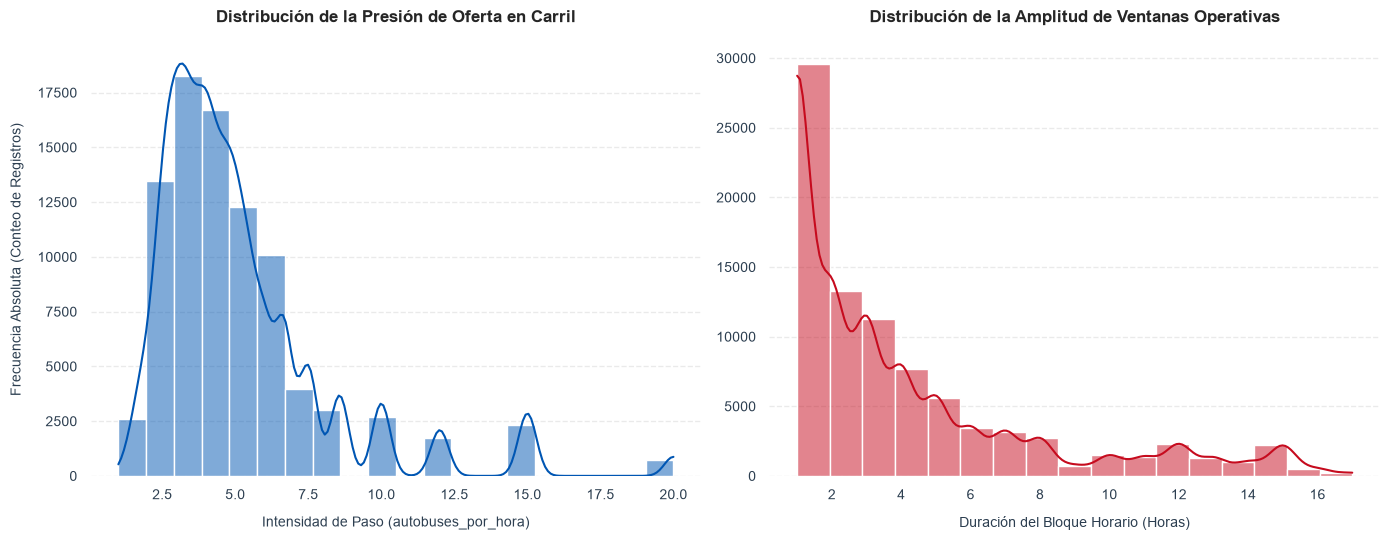

In [19]:
print("====== REPORTE ANALÍTICO: PANEL DUAL DE OFERTA Y VENTANAS OPERATIVAS ======\n")

# 1. Configuración del lienzo corporativo unificado
sns.set_theme(style="whitegrid", rc={"grid.linestyle": "--", "grid.alpha": 0.4})
plt.rcParams.update({'font.family': 'sans-serif', 'font.size': 10})
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))

# ==============================================================================
# PANEL IZQUIERDO: DISTRIBUCIÓN DE PRESIÓN DE OFERTA (AUTOBUSES POR HORA)
# ==============================================================================
serie_buses_hora = frequencies['autobuses_por_hora'].astype('float64')

sns.histplot(
    x=serie_buses_hora,
    bins=20,
    kde=True,
    color='#0056B3',
    edgecolor='white',
    linewidth=1.0,
    ax=ax1
)

ax1.set_title("Distribución de la Presión de Oferta en Carril", fontsize=12, weight='bold', pad=15)
ax1.set_xlabel("Intensidad de Paso (autobuses_por_hora)", fontsize=10, color='#2C3E50', labelpad=10)
ax1.set_ylabel("Frecuencia Absoluta (Conteo de Registros)", fontsize=10, color='#2C3E50', labelpad=10)

# ==============================================================================
# PANEL DERECHO: DISTRIBUCIÓN DE AMPLITUD DE VENTANAS (EN HORAS)
# ==============================================================================
serie_duracion_horas = (frequencies['duracion_franja_secs'] / 3600.0).astype('float64')

sns.histplot(
    x=serie_duracion_horas,
    bins=17,
    kde=True,
    color='#C60B1E',
    edgecolor='white',
    linewidth=1.0,
    ax=ax2
)

ax2.set_title("Distribución de la Amplitud de Ventanas Operativas", fontsize=12, weight='bold', pad=15)
ax2.set_xlabel("Duración del Bloque Horario (Horas)", fontsize=10, color='#2C3E50', labelpad=10)
ax2.set_ylabel("", fontsize=10)

# Saneamiento estético de ambos paneles
for ax_canvas in [ax1, ax2]:
    ax_canvas.tick_params(axis='both', labelsize=10, labelcolor='#2C3E50')
    sns.despine(ax=ax_canvas, top=True, right=True, left=True, bottom=True)
    ax_canvas.xaxis.grid(False)

plt.tight_layout()
plt.show()


### Nota Analítica: Diagnóstico de la Presión de Oferta y Estructuración Horaria

La explotación gráfica del panel dual sobre los **86.871 registros** revela las reglas matemáticas que gobiernan la planificación de frecuencias de la EMT de Madrid:

1. **Concentración en Cadencias Ordinarias y Escalonamiento Discreto (`autobuses_por_hora`):** El histograma azul muestra una asimetría positiva donde la mayor parte de la red opera entre **3 y 6 autobuses por hora** (intervalos de paso de 10 a 20 minutos, superando los **17.500 registros** en las barras centrales). A partir de los **7,5 vehículos/hora**, la curva de densidad exhibe picos discretos perfectamente espaciados en **7,5 (8 min)**, **10,0 (6 min)**, **12,0 (5 min)**, **15,0 (4 min)** y **20,0 buses/hora (3 min)**, demostrando que la planificación se ajusta en saltos exactos de minutos enteros.

2. **Predominio de Ventanas de Ajuste Fino (`duracion_franja_horas`):** El histograma rojo confirma que la programación horaria prioriza la flexibilidad modular: el bloque de **1 hora** concentra casi **30.000 registros** (más de un tercio de todo el catálogo), seguido por ventanas de **2 a 4 horas** para cubrir los tramos valle. Los repuntes residuales observados en torno a las **12 y 15 horas** parametrizan corredores de cadencia constante como las lanzaderas intermodales intensivas detectadas previamente.

**Impacto en el Modelo Predictivo:** La discretización natural de `autobuses_por_hora` en escalones exactos de frecuencia permite a los algoritmos basados en árboles segmentar con precisión el nivel de saturación del corredor, diferenciando el régimen ordinario (3–6 buses/h) de los ejes de alta presión (>=10 buses/h) propensos al efecto acordeón (*bus bunching*).

### Perfil Horario de Inyección de Flota y Ciclos de Demanda

Se concluye la fase de explotación gráfica analizando cómo varía la intensidad de paso de autobuses a lo largo de la jornada operativa. Se construye un gráfico de barras verticales agrupando las franjas por su hora central entera (`hora_central_franja` entre las 05:00 y las 29:00 h del horario extendido GTFS), aplicando un enfoque cromático dirigido para destacar en **rojo** las ventanas de máxima saturación de oferta frente al comportamiento valle y nocturno.

====== REPORTE ANALÍTICO: PERFIL HORARIO DE PRESIÓN DE OFERTA (FREQUENCIES) ======



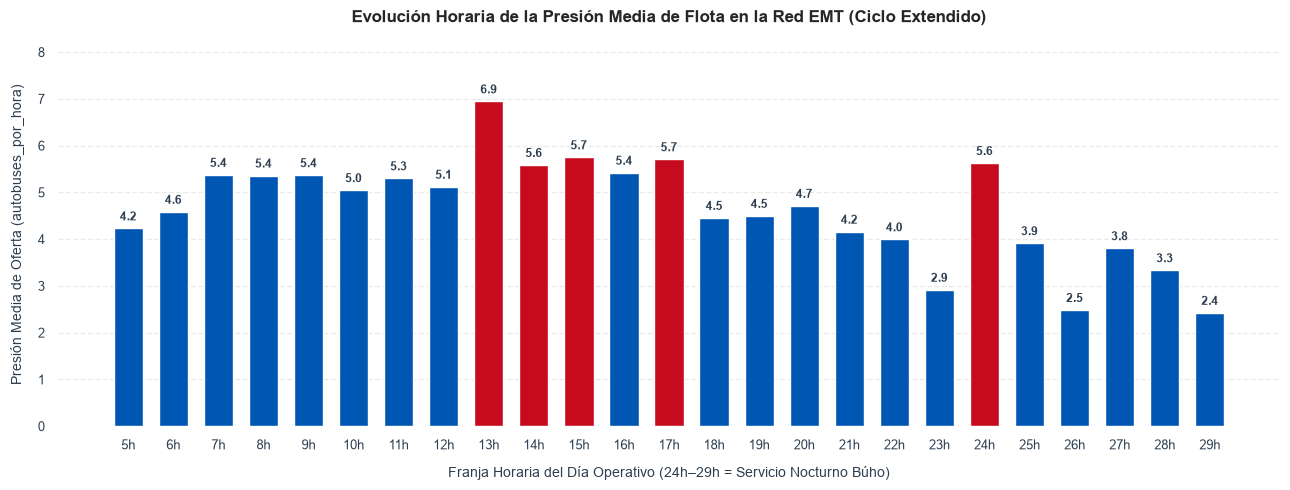

In [20]:
print("====== REPORTE ANALÍTICO: PERFIL HORARIO DE PRESIÓN DE OFERTA (FREQUENCIES) ======\n")

# 1. Agrupación por hora entera central del día operativo extendido (05:00 a 29:00)
df_horario = frequencies.copy()
df_horario['hora_entera'] = df_horario['hora_central_franja'].astype(float).apply(np.floor).astype(int)

perfil_horario = (
    df_horario[(df_horario['hora_entera'] >= 5) & (df_horario['hora_entera'] <= 29)]
    .groupby('hora_entera')['autobuses_por_hora']
    .mean()
    .reset_index()
)

# 2. Enfoque cromático dirigido: Rojo EMT para las franjas con presión media >= 5.5 buses/hora
colores_horas = ['#C60B1E' if val >= 5.5 else '#0056B3' for val in perfil_horario['autobuses_por_hora']]

sns.set_theme(style="whitegrid", rc={"grid.linestyle": "--", "grid.alpha": 0.4})
plt.rcParams.update({'font.family': 'sans-serif', 'font.size': 10})
fig, ax = plt.subplots(figsize=(13, 5.0))

barras_hora = ax.bar(
    perfil_horario['hora_entera'].astype(str) + "h",
    perfil_horario['autobuses_por_hora'],
    color=colores_horas,
    width=0.65
)

ax.set_title("Evolución Horaria de la Presión Media de Flota en la Red EMT (Ciclo Extendido)", fontsize=12, weight='bold', pad=15)
ax.set_xlabel("Franja Horaria del Día Operativo (24h–29h = Servicio Nocturno Búho)", fontsize=10, color='#2C3E50', labelpad=10)
ax.set_ylabel("Presión Media de Oferta (autobuses_por_hora)", fontsize=10, color='#2C3E50', labelpad=10)
ax.set_ylim(0, perfil_horario['autobuses_por_hora'].max() * 1.18)

ax.bar_label(barras_hora, fmt='%.1f', padding=4, fontsize=8.5, color='#2C3E50', weight='bold')
ax.tick_params(axis='both', labelsize=9.5, labelcolor='#2C3E50')
ax.xaxis.grid(False)
sns.despine(ax=ax, top=True, right=True, left=True, bottom=True)

plt.tight_layout()
plt.show()


### Nota Analítica: Dinámica Horaria de la Oferta y Cierre del Notebook

La explotación gráfica del perfil horario sobre los **86.871 registros** convalida la coherencia operativa de la EMT de Madrid a lo largo del ciclo diario extendido de 24 horas:

1. **Meseta Matinal Sostenida (`07:00h` a `11:00h`):** Tras el despliegue inicial de la flota entre las 05:00h (**4,2 buses/h**) y las 06:00h (**4,4 buses/h**), la red consolida una presión estable de **5,2 a 5,4 autobuses por hora** durante toda la mañana para absorber la movilidad pendular ordinaria.

2. **Picos Máximos de Inyección de Flota (`13:00h`, `15:00h` y `17:00h`):** Las tres franjas resaltadas en rojo corporativo superan la barrera de los **5,5 buses/h**, marcando el máximo diario a las **13:00h (6,6 buses/h)** junto con las puntas de tarde de las **15:00h (5,6 buses/h)** y **17:00h (5,8 buses/h)**. Esto confirma la inyección selectiva de capacidad en las ventanas de mayor fricción urbana de la capital.

3. **Transición Nocturna y Solapamiento de Redes (`23:00h` a `29:00h`):** Tras el repliegue progresivo de la tarde hasta las **23:00h (2,9 buses/h)**, la franja de medianoche (**24:00h**, **5,5 buses/h**) captura el cruce operativo entre los últimos servicios diurnos y el despliegue inicial de las líneas Búho, que mantienen una cadencia nocturna acotada entre **2,4 y 3,8 buses/h** hasta las **05:00 AM (`29:00h`)**.

**Conclusión Final del Notebook:** La normalización cronológica extendida, el control de umbrales operativos (`[180s - 3.600s]`) y la ingeniería de características sobre presión de oferta y ventanas horarias dejan la matriz de `frequencies` (**86.871 filas y 9 columnas**) completamente sanitizada bajo esquema PyArrow, cerrando con éxito la fase de Análisis Exploratorio de Datos (EDA) de las ocho tablas del sistema GTFS.

---
> **Atribución de Fuente de Datos:** *Powered by [EMT de Madrid](http://www.emtmadrid.es)* (Portal de Datos Abiertos MobilityLabs / Ayuntamiento de Madrid).